In [ ]:
import os
import warnings
import joblib
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_squared_log_error, r2_score, accuracy_score, confusion_matrix, classification_report
from sklearn.model_selection import ParameterGrid
from joblib import Parallel, delayed 
from sklearn import ensemble, linear_model, svm
from sklearn.preprocessing import RobustScaler, MinMaxScaler
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from sklearn.model_selection import RandomizedSearchCV, GridSearchCV
from lazy_test import *
from success_utils import *

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Create a dictionary to group countries by region
region_groups = {
    "North America": ["HI", "Mexico", "NV", "OK", "NM","CA", "NY", "MD", "DC", "WA", "CO", "MN", "TX", "SC", "GA", "KY", "PA", "MI", "OH", "OR", "NC", "IL", "AZ", "TN", "NJ", "UT", "VA", "ND", "VT", "IA", "ND", "VT", "LA", "CT", "RI"],
    "Europe": ["Martinique", "AL", "Cayman Islands", "Russia", "ME", "UK", "DE", "Poland", "Denmark", "Netherlands", "Norway", "Liechtenstein", "Austria", "Belgium", "Czech Republic", "Iceland", "Ireland", "France", "Spain", "Sweden", "Switzerland", "Italy", "Slovenia", "Greece"],
    "Asia": ["MO", "IN", "Japan", "China", "Hong Kong", "India", "Viet Nam", "Taiwan", "Afghanistan", "Israel","Sri Lanka", "Jordan"],
    "South America": ["Colombia", "Brazil"],
    "Africa": ["WI", "SD", "MA", "Ghana", "Ethiopia", "Liberia", "Rwanda"],
    "Oceania": ["AU", "NZ"],
    "Other": [ "United Arab Emirates", "Svalbard and Jan Mayen"]
}

noticable_entities = ['ORG', 'PERSON', 'DATE',
                        'CARDINAL', 'GPE', 'PRODUCT', 
                        'WORK_OF_ART','ORDINAL', 'MONEY',
                        'TIME', 'NORP']


data_path = '/home/theerthala/Documents/repos/Crowdfunding-Social-Media-Drivers/Data/Kickstarter_only/final_data.csv'
success_data = pd.read_csv(data_path)
success_data['collection_ratio'] = success_data.collected.apply(decode_amount)/success_data.goal_amount.apply(decode_amount)


bins = [0, 7, 14, 30, 60]
labels = ['<1 week', '1-2 weeks', '2 weeks - 1 month', '1-2 months']
success_data['duration'] = pd.cut(success_data['duration'], bins=bins, labels=labels)
success_data= success_data[success_data.donate != 1].reset_index(drop=True)


success_weights = (1-success_data.success.value_counts()/len(success_data)).values


def get_region(country):
    for region, countries in region_groups.items():
        if country in countries:
            return region
    return "Other"

success_data['region'] = success_data.country.str.strip().apply(get_region)
success_data.num_backers = success_data.num_backers.str.replace(',', '').astype(int)
success_data = success_data[success_data.region == 'North America']

success_data = pd.get_dummies(
                    success_data,
                    columns=['fb_type', 
                              'duration'])


for entity in noticable_entities:
    success_data[f'fb_entity_{entity}'] = success_data.fb_entities_identified.fillna('None').str.split(',').apply(lambda entity_list: entity in entity_list).astype(int)
    

bool_cols = success_data.dtypes[success_data.dtypes == 'bool'].index.tolist()
success_data[bool_cols] = success_data[bool_cols].astype(int)

#ecoding the number of backers
success_data.num_backers = encode_targets(success_data.num_backers)
success_data.population = np.exp(success_data.population)


success_data.head()

In [ ]:
dropping_columns = ['collected', 'verified', 'donate', 'project_we_love', 'Team' ,'country', 'fb_page_name', 'region', 'fb_entities_identified', 'population', 'category']

success_data.drop(columns=dropping_columns, axis=1, inplace=True)
success_data = success_data[success_data.collection_ratio < 10].reset_index(drop=True)
success_data.pledge_types = success_data.pledge_types.astype(int)
success_data.num_projects = success_data.num_projects.astype(int)
success_data.num_backed = success_data.num_backed.astype(int)


In [ ]:
#identify and list all the boolean features disguised as int in the dataset
bool_features = []
for col in success_data.columns:
    if success_data[col].nunique() == 2:
        bool_features.append(col)

bool_features.remove('success')

In [ ]:
entity_features = [x for x in bool_features if 'fb_entity' in x]
duration_features = [x for x in bool_features if 'duration' in x]
region_features = [x for x in bool_features if 'region' in x]


In [ ]:
# success_data.num_backers = np.exp(success_data.num_backers)
target_cols = [
    'success',
    'collection_ratio',
    'num_backers'
]

#adding emotionality score
emotion_cols = ['fb_fear','fb_anger', 'fb_anticip', 'fb_trust', 'fb_surprise', 'fb_positive', 'fb_negative', 'fb_sadness', 'fb_disgust', 'fb_joy']
success_data['fb_emotionality'] = success_data[emotion_cols].sum(axis=1)

fb_cols = success_data.columns[success_data.columns.str.startswith('fb')].tolist()
common_features= success_data.columns[~success_data.columns.str.startswith('fb')].tolist()
common_features = [feature for feature in common_features if feature not in target_cols]
common_features.remove("pledge_types")

engagement_features = [ 'fb_likes', 'fb_comments', 'fb_shares','fb_positive_reactions','fb_negative_reactions']
post_fb_features = [feature for feature in fb_cols if feature not in engagement_features]


In [ ]:
domain_page_features = success_data[common_features]
domain_engagement_features = success_data[common_features + engagement_features]
domain_post_features = success_data[common_features + post_fb_features]

targets = success_data[target_cols]

In [ ]:
pd.concat([domain_page_features, targets], axis=1).to_csv('/home/theerthala/Documents/repos/Crowdfunding-Social-Media-Drivers/Data/final_datasets/domain_only.csv', index=False)
pd.concat([domain_engagement_features, targets], axis=1).to_csv('/home/theerthala/Documents/repos/Crowdfunding-Social-Media-Drivers/Data/final_datasets/domain_engagement.csv', index=False)
pd.concat([domain_post_features, targets], axis=1).to_csv('/home/theerthala/Documents/repos/Crowdfunding-Social-Media-Drivers/Data/final_datasets/domain_post.csv', index=False)

In [ ]:
print(common_features)

## Modelling

In [ ]:
working_data = 'domain_post'
domain_post = pd.read_csv(f'/home/theerthala/Documents/repos/Crowdfunding-Social-Media-Drivers/Data/final_datasets/{working_data}.csv')
domain_post.num_backers = np.exp(domain_post.num_backers)

In [ ]:
domain_post.loc[:,target_cols].head()

In [ ]:
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(domain_post.drop(target_cols, axis=1), domain_post[target_cols], test_size=0.13, random_state=42, stratify=domain_post.success)

X_train = X_train.reset_index(drop=True).values
X_test = X_test.reset_index(drop=True).values
y_train = y_train.reset_index(drop=True).values
y_test = y_test.reset_index(drop=True).values

* y[:, 0] => Success (Boolean)
* y[:,1] => Collection Ratio
* y[:,2] => Number of Backers


In [ ]:
reg_test = RegressionModels(X_train, X_test, y_train[:,2], y_test[:,2], decode=False)
reg_test.run_evaluation()
print(reg_test.not_trained_)
print(reg_test.not_evaluated_)
reg_test.all_scores.to_csv("/home/theerthala/Documents/repos/Crowdfunding-Social-Media-Drivers/Results/02 - Domain Post/num_backers/lazy_scores.csv")
reg_test.top_10_socres

In [ ]:
cls_test = ClassificationModels(X_train, X_test, y_train[:,0], y_test[:,0])
cls_test.run_evaluation()
print(cls_test.not_trained_)
print(cls_test.not_evaluated_)
cls_test.all_scores.to_csv("/home/theerthala/Documents/repos/Crowdfunding-Social-Media-Drivers/Results/02 - Domain Post/success/lazy_scores.csv")
cls_test.top_10_socres

## Further Finetuning of the topk models

### Collection Ratio

In [ ]:
reg_test = RegressionModels(X_train, X_test, y_train[:,1], y_test[:,1], decode=False)
reg_test.run_evaluation()
print(reg_test.not_trained_)
print(reg_test.not_evaluated_)
reg_test.all_scores.to_csv("/home/theerthala/Documents/repos/Crowdfunding-Social-Media-Drivers/Results/02 - Domain Post/collection_ratio/lazy_scores.csv")
reg_test.top_10_socres

In [ ]:
elastic_net = linear_model.ElasticNet(random_state=42)
elastic_net.fit(X_train, y_train[:,1])

in_y_pred = elastic_net.predict(X_train)
out_y_pred = elastic_net.predict(X_test)

print(f'In-sample RMSE, R2: {np.sqrt(mean_squared_error(y_train[:,1], in_y_pred)):.2f}, {r2_score(y_train[:,1], in_y_pred)}')
print(f'Out-sample RMSE, R2: {np.sqrt(mean_squared_error(y_test[:,1], out_y_pred)):.2f}, {r2_score(y_test[:,1], out_y_pred)}')

In [ ]:
lars_cv = linear_model.LarsCV(cv=20)
lars_cv.fit(X_train, y_train[:,1])

y_pred_in = lars_cv.predict(X_train)
y_pred_out = lars_cv.predict(X_test)

print(f'RMSE In: {np.sqrt(mean_squared_error(y_train[:,1], y_pred_in)):.2f}')
print(f'RMSE Out: {np.sqrt(mean_squared_error(y_test[:,1], y_pred_out)):.2f}')

print(f'R2 In: {r2_score(y_train[:,1], y_pred_in)}')
print(f'R2 Out: {r2_score(y_test[:,1], y_pred_out)}')

In [ ]:
ridge_cv = linear_model.RidgeCV(cv=20)
ridge_cv.fit(X_train, y_train[:,1])

y_pred_in = ridge_cv.predict(X_train)
y_pred_out = ridge_cv.predict(X_test)

print(f'RMSE In: {np.sqrt(mean_squared_error(y_train[:,1], y_pred_in)):.2f}')
print(f'RMSE Out: {np.sqrt(mean_squared_error(y_test[:,1], y_pred_out)):.2f}')

print(f'R2 In: {r2_score(y_train[:,1], y_pred_in)}')
print(f'R2 Out: {r2_score(y_test[:,1], y_pred_out)}')

In [ ]:
joblib.dump(lars_cv, '/home/theerthala/Documents/repos/Crowdfunding-Social-Media-Drivers/Modelling/final_models/02_domain_post/collection_ratio.pkl')

### Number of Backers

In [ ]:
ridge_cv = linear_model.RidgeCV(cv=10)
ridge_cv.fit(X_train, y_train[:,2])

y_pred_in = ridge_cv.predict(X_train)
y_pred_out = ridge_cv.predict(X_test)

print(f'RMSE In: {np.sqrt(mean_squared_error(y_train[:,2], y_pred_in)):.2f}')
print(f'RMSE Out: {np.sqrt(mean_squared_error(y_test[:,2], y_pred_out)):.2f}')

print(f'R2 In: {r2_score(y_train[:,2], y_pred_in)}')
print(f'R2 Out: {r2_score(y_test[:,2], y_pred_out)}')

In [ ]:
lars_cv = linear_model.LarsCV(cv=10)
lars_cv.fit(X_train, y_train[:,2])

y_pred_in = lars_cv.predict(X_train)
y_pred_out = lars_cv.predict(X_test)

print(f'RMSE In: {np.sqrt(mean_squared_error(y_train[:,2], y_pred_in)):.2f}')
print(f'RMSE Out: {np.sqrt(mean_squared_error(y_test[:,2], y_pred_out)):.2f}')

print(f'R2 In: {r2_score(y_train[:,2], y_pred_in)}')
print(f'R2 Out: {r2_score(y_test[:,2], y_pred_out)}')

In [ ]:
poisson = linear_model.PoissonRegressor()
poisson.fit(X_train, y_train[:,2])

y_pred_in = poisson.predict(X_train)
y_pred_out = poisson.predict(X_test)

print(f'RMSE In: {np.sqrt(mean_squared_error(y_train[:,2], y_pred_in)):.2f}')
print(f'RMSE Out: {np.sqrt(mean_squared_error(y_test[:,2], y_pred_out)):.2f}')

print(f'R2 In: {r2_score(y_train[:,2], y_pred_in)}')
print(f'R2 Out: {r2_score(y_test[:,2], y_pred_out)}')

In [ ]:
joblib.dump(lars_cv, '/home/theerthala/Documents/repos/Crowdfunding-Social-Media-Drivers/Modelling/final_models/02_domain_post/num_backers.pkl')

> Despite the encoded targets showing very good R2, when decoded, the R2 is not as good. 

Before Decoding: 

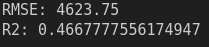

After Decoding:

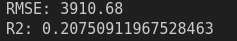

Hence, the best model with un-encoded training, is further finetuned. 

### Success

In [ ]:
balanced_bagging = BalancedBaggingClassifier(random_state=42, n_jobs=-1)
balanced_bagging.fit(X_train, y_train[:,0])

y_pred_in = balanced_bagging.predict(X_train)
y_pred_out = balanced_bagging.predict(X_test)

print(f'Accuracy In: {accuracy_score(y_train[:,0], y_pred_in)}')
print(f'Accuracy Out: {accuracy_score(y_test[:,0], y_pred_out)}')

def get_class_wise_acc(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    return cm[0,0]/cm[0].sum(), cm[1,1]/cm[1].sum()

print(f'Classwise Accuracy In: {get_class_wise_acc(y_train[:,0], y_pred_in)}')
print(f'Classwise Accuracy Out: {get_class_wise_acc(y_test[:,0], y_pred_out)}')


In [ ]:
easy_ensemble = EasyEnsembleClassifier(random_state=42, n_jobs=-1)
easy_ensemble.fit(X_train, y_train[:,0])

y_pred_in = easy_ensemble.predict(X_train)
y_pred_out = easy_ensemble.predict(X_test)

print(f'Accuracy In: {accuracy_score(y_train[:,0], y_pred_in)}')
print(f'Accuracy Out: {accuracy_score(y_test[:,0], y_pred_out)}')

print(f'Classwise Accuracy In: {get_class_wise_acc(y_train[:,0], y_pred_in)}')
print(f'Classwise Accuracy Out: {get_class_wise_acc(y_test[:,0], y_pred_out)}')


In [ ]:
joblib.dump(easy_ensemble, '/home/theerthala/Documents/repos/Crowdfunding-Social-Media-Drivers/Modelling/final_models/02_domain_post/success.pkl')

## Insample and outof sample tests

In [ ]:
num_backers_model =  joblib.load( '/home/theerthala/Documents/repos/Crowdfunding-Social-Media-Drivers/Modelling/final_models/02_domain_post/num_backers.pkl')
collection_model = joblib.load('/home/theerthala/Documents/repos/Crowdfunding-Social-Media-Drivers/Modelling/final_models/02_domain_post/collection_ratio.pkl')
success_model = joblib.load('/home/theerthala/Documents/repos/Crowdfunding-Social-Media-Drivers/Modelling/final_models/02_domain_post/success.pkl')

In [ ]:
#insample scores
print('Insample Scores')
y_pred = num_backers_model.predict(X_train)
print(f'RMSE: {np.sqrt(mean_squared_error(y_train[:,2], y_pred)):.3f}')

y_pred = collection_model.predict(X_train)
print(f'RMSE: {np.sqrt(mean_squared_error(y_train[:,1], y_pred)):.2f}')

y_pred = success_model.predict(X_train)
print(f'Accuracy: {accuracy_score(y_train[:,0], y_pred)}')

print()
#out-of-sample scores
print('Out of Sample')
y_pred = num_backers_model.predict(X_test)
print(f'RMSE: {np.sqrt(mean_squared_error(y_test[:,2], y_pred)):.3f}')

y_pred = collection_model.predict(X_test)
print(f'RMSE: {np.sqrt(mean_squared_error(y_test[:,1], y_pred)):.2f}')

y_pred = success_model.predict(X_test)
print(f'Accuracy: {accuracy_score(y_test[:,0], y_pred)}')

In [ ]:
domain_post_features.columns